# ACTG 175: predicting an AIDS-defining event or death with five classifiers
**M.Tech (AIML) · Machine Learning · Assignment 2**
Student: **Mani Rathinam Subbaiah** · BITS ID **2026AJ05440**

This notebook covers the whole modelling workflow: load → understand → clean → split → preprocess → tune → evaluate → save.
It produces every number in `README.md` and every artefact the Streamlit app (`app.py`) loads.
Run it top to bottom from the repository root (`Kernel → Restart & Run All`).

In [1]:
import getpass
import json
import platform
import socket
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, matthews_corrcoef, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
if not (ROOT / "actg_eval.py").exists():  # notebook opened from a sub-folder
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import actg_eval as ev  # shared schema + metric definitions (also used by app.py)

SEED = 5440        # last four digits of BITS ID 2026AJ05440; fixes every random step
TEST_SIZE = 0.20   # 80 / 20 stratified hold-out
DATA_DIR, MODEL_DIR, RESULTS_DIR = ROOT / "data", ROOT / "model", ROOT / "results"
MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40, "display.width", 160)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.17 | scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.2.6


## 1. Load the data
**AIDS Clinical Trials Group Study 175** from the UCI Machine Learning Repository ([dataset 890](https://archive.ics.uci.edu/dataset/890/aids+clinical+trials+group+study+175)).
The trial compared four antiretroviral regimens in HIV-infected adults with CD4 counts of 200–500 cells/mm³ (Hammer et al., *NEJM* 1996).
Each row is one patient. The target `cid` is 1 if the patient had an AIDS-defining event or died during follow-up, and 0 if they were censored.
The repository keeps a copy in `data/actg175_raw.csv`; if it is missing, the cell downloads it with `ucimlrepo`.

In [2]:
raw_path = DATA_DIR / "actg175_raw.csv"
if not raw_path.exists():
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=890)
    DATA_DIR.mkdir(exist_ok=True)
    pd.concat([uci.data.ids, uci.data.features, uci.data.targets], axis=1).to_csv(raw_path, index=False)

raw = pd.read_csv(raw_path)
print(f"Raw table: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

Raw table: 2139 rows x 25 columns


,pidnum,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,cid
0,10056,948,2,48,89.8128,0,0,0,100,0,0,1,0,0,0,0,1,0,1,0,422,477,566,324,0
1,10059,1002,3,61,49.4424,0,0,0,90,0,1,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,10089,961,3,45,88.4520,0,1,1,90,0,1,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,10093,1166,3,47,85.2768,0,1,0,100,0,1,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,10124,1090,0,43,66.6792,0,1,0,100,0,1,1,1352,0,1,1,3,0,0,0,504,353,870,782,0


## 2. Understand the data

In [3]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "min": raw.min(),
    "max": raw.max(),
})
print("Exact duplicate rows:", raw.duplicated().sum(),
      "| duplicates ignoring the patient ID:", raw.drop(columns="pidnum").duplicated().sum())
profile

Exact duplicate rows: 0 | duplicates ignoring the patient ID: 0


,dtype,missing,unique values,min,max
pidnum,int64,0,2139,10056.0,990077.00000
time,int64,0,713,14.0,1231.00000
trt,int64,0,4,0.0,3.00000
age,int64,0,59,12.0,70.00000
wtkg,float64,0,667,31.0,159.93936
hemo,int64,0,2,0.0,1.00000
homo,int64,0,2,0.0,1.00000
drugs,int64,0,2,0.0,1.00000
karnof,int64,0,4,70.0,100.00000
oprior,int64,0,2,0.0,1.00000


In [4]:
counts = raw[ev.TARGET_COL].value_counts().sort_index()
balance = pd.DataFrame({"patients": counts, "share %": (counts / counts.sum() * 100).round(1)})
balance.index = [f"{c} = {ev.CLASS_LABELS[c]}" for c in balance.index]
balance

,patients,share %
0 = No event (censored),1618,75.6
1 = AIDS event / death,521,24.4


The classes are imbalanced (about 3 : 1). A model that always predicts "no event" would already reach ~76% accuracy.
So accuracy alone is misleading here. **MCC** and **F1** for the event class are better guides, and MCC is the primary metric used for tuning.

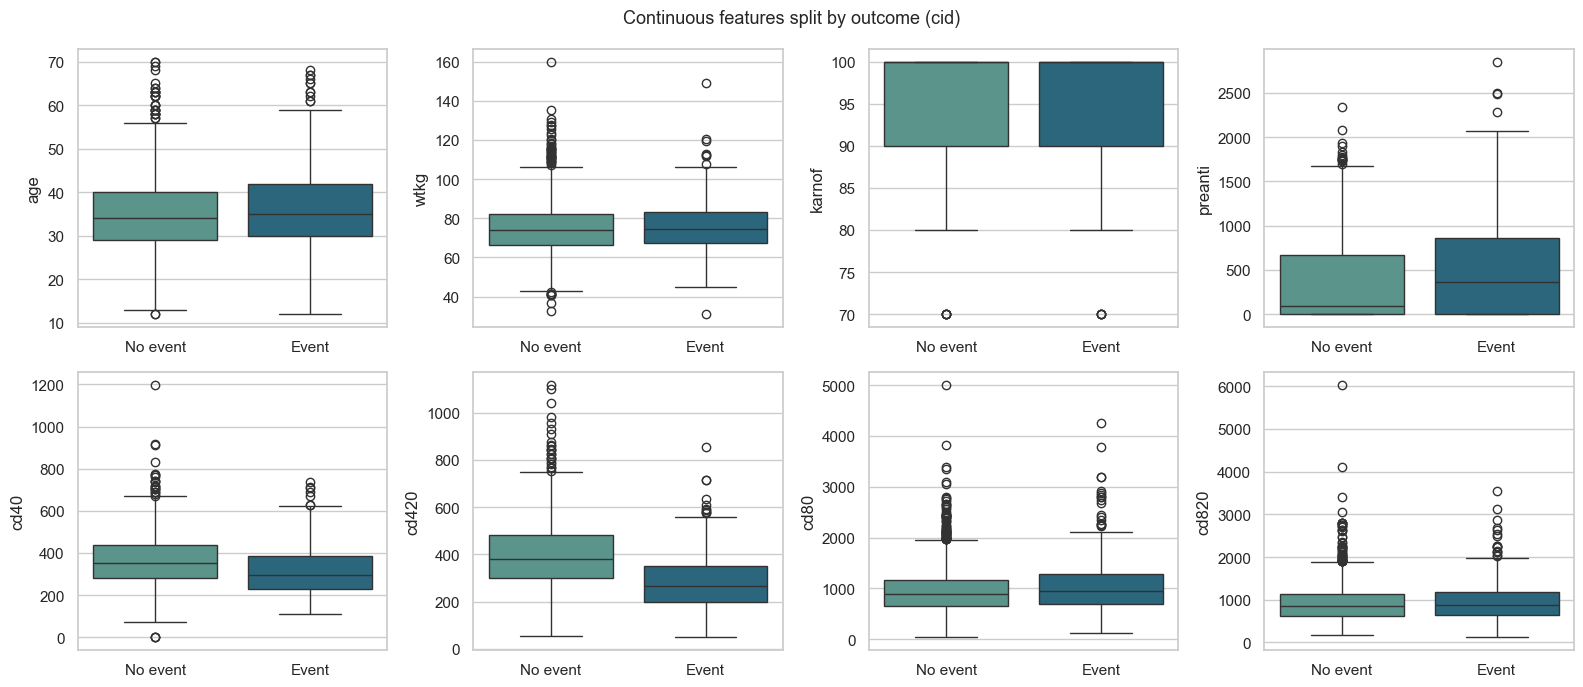

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, ev.CONTINUOUS_FEATURES):
    sns.boxplot(data=raw, x=ev.TARGET_COL, y=col, hue=ev.TARGET_COL, palette="crest", legend=False, ax=ax)
    ax.set_xticks([0, 1], ["No event", "Event"])
    ax.set_xlabel("")
fig.suptitle("Continuous features split by outcome (cid)", fontsize=13)
fig.tight_layout()
plt.show()

In [6]:
# Event rate (share of cid = 1) for each level of the binary / nominal features
event_rate = pd.DataFrame({col: raw.groupby(col)[ev.TARGET_COL].mean()
                           for col in ev.BINARY_FEATURES + ev.NOMINAL_FEATURES}).T
event_rate.columns = [f"level {c}" for c in event_rate.columns]
event_rate.round(3)

,level 0,level 1,level 2,level 3
hemo,0.245,0.228,NaN,NaN
homo,0.211,0.260,NaN,NaN
drugs,0.252,0.189,NaN,NaN
oprior,0.241,0.362,NaN,NaN
z30,0.184,0.292,NaN,NaN
race,0.259,0.206,NaN,NaN
gender,0.201,0.252,NaN,NaN
str2,0.181,0.288,NaN,NaN
symptom,0.218,0.365,NaN,NaN
treat,0.340,0.212,NaN,NaN


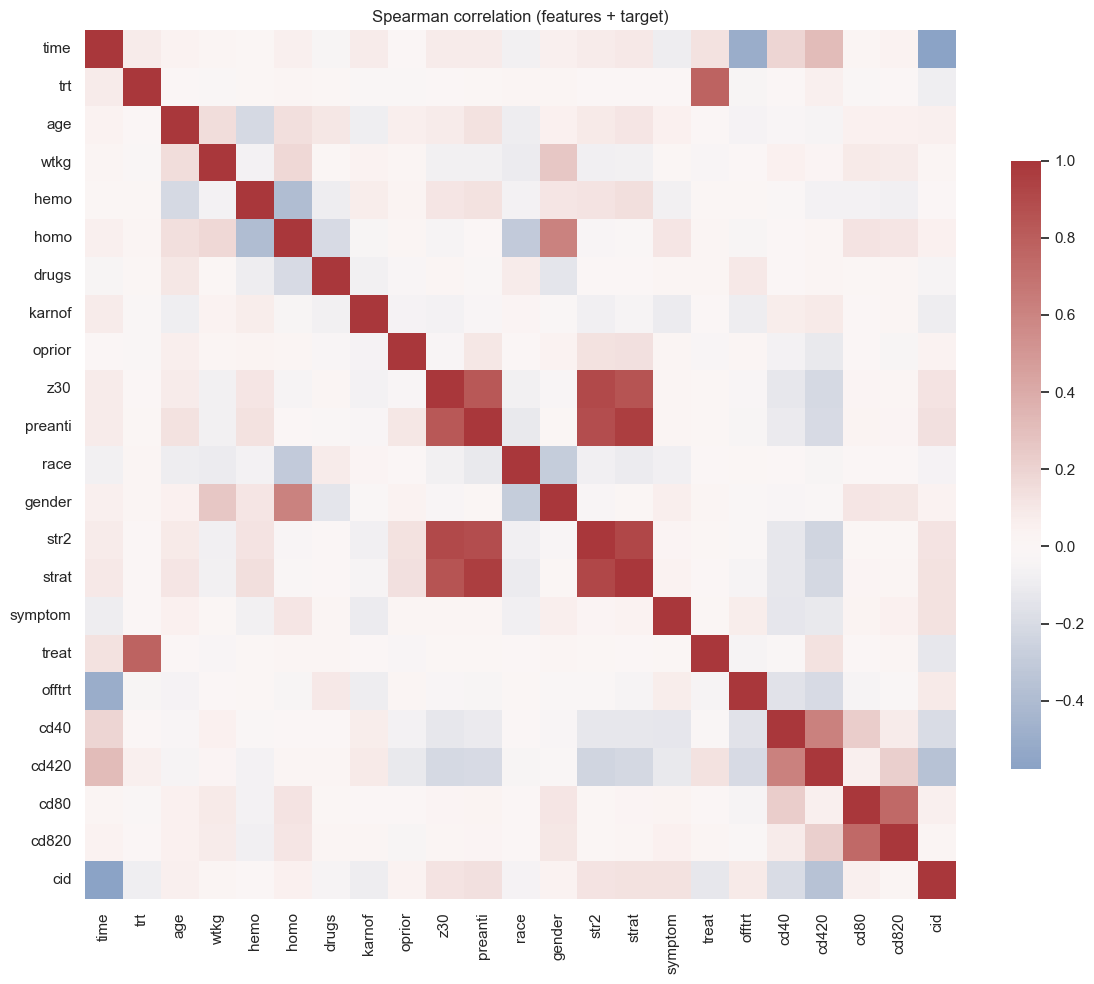

Strongest correlations with cid:
time       0.576
cd420      0.365
cd40       0.199
preanti    0.136
strat      0.131
treat      0.130


In [7]:
corr = raw.drop(columns=["pidnum", "zprior"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman correlation (features + target)")
fig.tight_layout()
plt.show()
print("Strongest correlations with cid:")
print(corr[ev.TARGET_COL].drop(ev.TARGET_COL).abs().sort_values(ascending=False).head(6).round(3).to_string())

## 3. Cleaning decisions
These steps are deterministic and learn nothing from the data, so it is safe to apply them before the split.

| Column | Action | Reason |
|---|---|---|
| `pidnum` | drop | Patient identifier, carries no clinical signal |
| `time` | drop | Days until the event or censoring. It is only known *after* the outcome, so it leaks the answer |
| `zprior` | drop | Constant: every patient has the value 1 |

There are no missing values and no duplicate rows. The imputers inside the pipelines stay in place anyway, so that a test file with blank cells can still be scored.

In [8]:
time_auc = roc_auc_score(raw[ev.TARGET_COL], -raw["time"])
print(f"'time' on its own separates the classes with ROC-AUC = {time_auc:.3f} -> target leakage, dropped.")
print("'zprior' unique values:", raw["zprior"].unique())

data = raw.drop(columns=list(ev.DROPPED_COLUMNS)).drop_duplicates().reset_index(drop=True)
assert sorted(data.columns) == sorted(ev.FEATURE_COLUMNS + [ev.TARGET_COL])

n_features = len(ev.FEATURE_COLUMNS)
print(f"Clean table: {len(data)} rows x {n_features} input features + target")
assert n_features >= 12 and len(data) >= 500, "Assignment minimum (12 features, 500 rows) not met"
print("Assignment minimums satisfied: >= 12 features and >= 500 instances")

'time' on its own separates the classes with ROC-AUC = 0.888 -> target leakage, dropped.
'zprior' unique values: [1]
Clean table: 2139 rows x 21 input features + target
Assignment minimums satisfied: >= 12 features and >= 500 instances


## 4. Stratified train / test split
The split is 80 / 20 and stratified on `cid`, so both parts keep the same event rate. The seed is fixed at 5440.
The 20% test part is saved as **`test_data.csv`**: the original 21 feature columns plus `cid`, untransformed.
It is used **only** for the final evaluation below, and it is the file to upload to the Streamlit app.

In [9]:
X = data[ev.FEATURE_COLUMNS]
y = data[ev.TARGET_COL].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

test_df = X_test.assign(**{ev.TARGET_COL: y_test}).reset_index(drop=True)
test_df.to_csv(ROOT / "test_data.csv", index=False)
print(f"test_data.csv written: {test_df.shape[0]} rows x {test_df.shape[1]} columns")

pd.DataFrame({"rows": [len(y_train), len(y_test)],
              "event share %": [y_train.mean() * 100, y_test.mean() * 100]},
             index=["train", "test"]).round(2)

test_data.csv written: 428 rows x 22 columns


,rows,event share %
train,1711,24.37
test,428,24.30
